# Análisis Exploratorio de Datos (EDA)

In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np 
import pandas as pd 

import matplotlib.pyplot as plt 
import seaborn as sns 

# Cargar el Dataset
df = pd.read_csv('data/retailmax.csv')

# 1. ¿Cuál es la distribución de edades de los clientes?

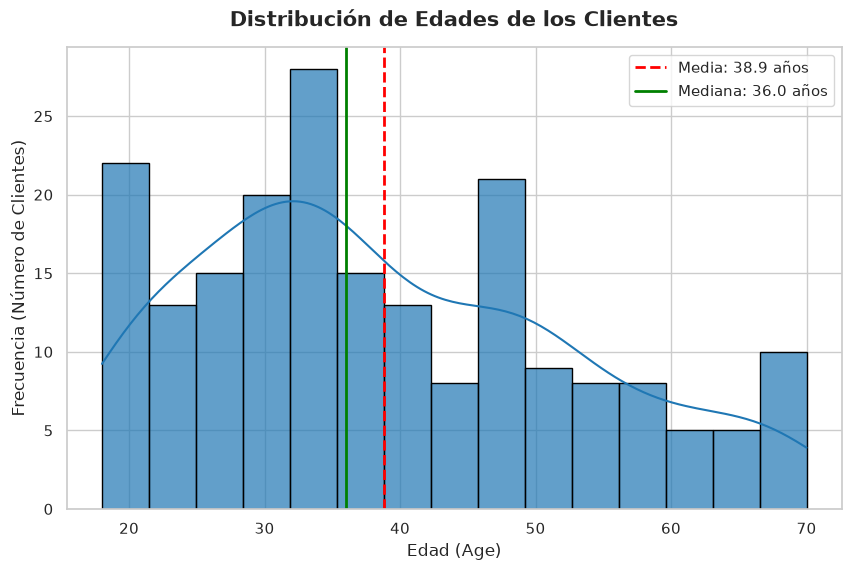

In [4]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(10, 6))
sns.histplot(df['Age'], bins=15, kde=True, color='#1f77b4', edgecolor='black', alpha=0.7)
plt.title('Distribución de Edades de los Clientes', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Edad (Age)', fontsize=12)
plt.ylabel('Frecuencia (Número de Clientes)', fontsize=12)
plt.axvline(df['Age'].mean(), color='red', linestyle='--', linewidth=2, label=f'Media: {df["Age"].mean():.1f} años')
plt.axvline(df['Age'].median(), color='green', linestyle='-', linewidth=2, label=f'Mediana: {df["Age"].median():.1f} años')
plt.legend(fontsize=11)
plt.show()

# 2. ¿Existen diferencias en los ingresos anuales entre hombres y mujeres?

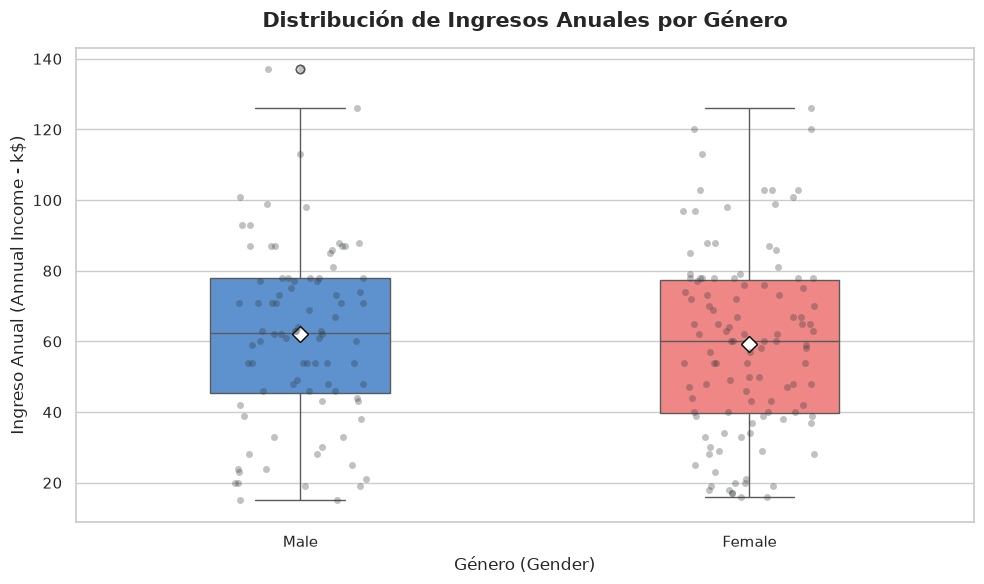

In [5]:
plt.figure(figsize=(10, 6))

# Gráfico de caja (boxplot) con strip plot superpuesto para ver la distribución individual
sns.boxplot(
    data=df, 
    x='Gender', 
    y='Annual Income (k$)', 
    palette={'Male': '#4a90e2', 'Female': '#ff7675'},
    width=0.4,
    showmeans=True,
    meanprops={"marker":"D", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"}
)

# Mostrar los puntos individuales de datos de manera sutil
sns.stripplot(
    data=df, 
    x='Gender', 
    y='Annual Income (k$)', 
    color='#2d3436', 
    alpha=0.3, 
    jitter=0.15, 
    size=5
)

plt.title('Distribución de Ingresos Anuales por Género', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Género (Gender)', fontsize=12)
plt.ylabel('Ingreso Anual (Annual Income - k$)', fontsize=12)

plt.tight_layout()
plt.show()

### **Análisis de los Resultados**

Al analizar la distribución de ingresos anuales entre hombres y mujeres, observamos que **no existen diferencias drásticas**, aunque sí se aprecian ligeras variaciones a favor del grupo masculino:

1. **Promedio (Media) y Mediana:**
   - Los **hombres** tienen un ingreso anual promedio de **62.23 k$** y una mediana de **62.50 k$**.
   - Las **mujeres** tienen un ingreso anual promedio de **59.25 k$** y una mediana de **60.00 k$**.
   - Esto representa una ligera diferencia de **~2.98 k$ en la media** y **2.50 k$ en la mediana** a favor de los hombres.

2. **Dispersión y Límites:**
   - La dispersión (desviación estándar) es sumamente similar en ambos grupos: **26.64 k$** para hombres y **26.01 k$** para mujeres.
   - Los rangos intercuartílicos y las cajas en el gráfico muestran que el 50% central de la población se encuentra en rangos muy similares, aunque el límite inferior del 25% de los hombres (45.5 k$) es ligeramente mayor al de las mujeres (39.75 k$).
   - El ingreso máximo registrado pertenece a un hombre con **137 k$**, mientras que el de las mujeres es de **126 k$**.

**Conclusión:** Aunque estadísticamente los hombres muestran ingresos ligeramente superiores en términos de medidas de tendencia central (media y mediana) y valores máximos, las distribuciones se superponen en gran medida. Esto sugiere que **el género no es un factor determinante o altamente diferenciador** para el nivel de ingresos en este conjunto de datos.

# 3. ¿Cómo se distribuye la puntuación de gastos entre los diferentes rangos de edades?

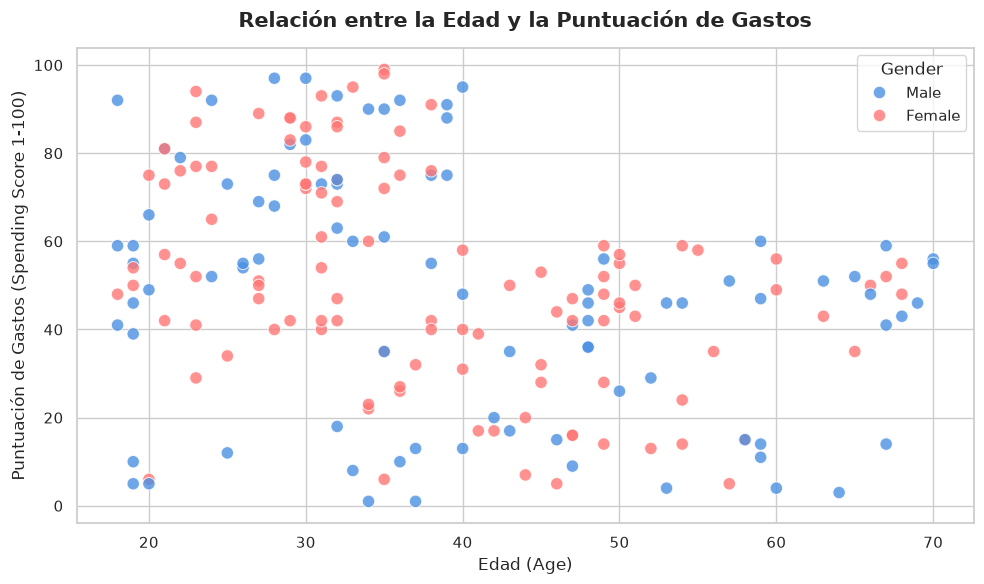

In [6]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age',
    y='Spending Score (1-100)',
    hue='Gender',
    palette={'Male': '#4a90e2', 'Female': '#ff7675'},
    alpha=0.8,
    s=80
)

plt.title('Relación entre la Edad y la Puntuación de Gastos', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Edad (Age)', fontsize=12)
plt.ylabel('Puntuación de Gastos (Spending Score 1-100)', fontsize=12)
plt.tight_layout()
plt.show()

### **Análisis de los Resultados**

Al analizar la distribución de la puntuación de gastos (`Spending Score (1-100)`) en función de la edad (`Age`), podemos extraer conclusiones muy claras y valiosas sobre el comportamiento de los clientes:

1. **Límite de Edad para Altos Consumidores:**
   - Se observa una clara barrera alrededor de los **40 años**. Prácticamente **ningún cliente mayor de 40 años supera una puntuación de gasto de 60**.
   - La gran mayoría de los clientes de más de 40 años se concentra en un rango de puntuación moderado y bajo (entre 1 y 60 puntos), con una media que ronda los **32-34 puntos**.

2. **Comportamiento en Clientes Jóvenes (< 40 años):**
   - Los clientes de entre 18 y 40 años muestran una dispersión mucho mayor y son los únicos que alcanzan puntuaciones de gastos sobresalientes (entre 60 y 100 puntos).
   - En este segmento joven, se aprecian claramente dos grupos bien diferenciados: uno de perfil muy ahorrador/moderado (puntuaciones bajas) y otro de perfil altamente consumidor (puntuaciones que van de 60 a 99 puntos).

**Conclusión:** La edad es un factor altamente segmentador en este conjunto de datos. Mientras que los clientes jóvenes (< 40 años) presentan un grupo con potencial de compra sumamente elevado, el segmento de mayor edad (>= 40 años) exhibe un comportamiento de gasto mucho más moderado y homogéneo, sin superar nunca la franja alta de puntuación.

# 4. ¿Cuál es la correlación entre el ingreso anual y la puntuación de gasto?

Objetivo: Identificar si existe una relación lineal entre el ingreso y el gasto.

Respuesta esperada: Una gráfica de dispersión y el cálculo del coeficiente de correlación entre Annual Income (k$) y Spending Score (1-100).

In [7]:
# Correlación entre ingreso anual y puntuación de gasto
corr = df['Annual Income (k$)'].corr(df['Spending Score (1-100)'])
print(f'La correlación entre ingreso anual y puntuación de gasto es: {corr:.3f}')

La correlación entre ingreso anual y puntuación de gasto es: 0.010


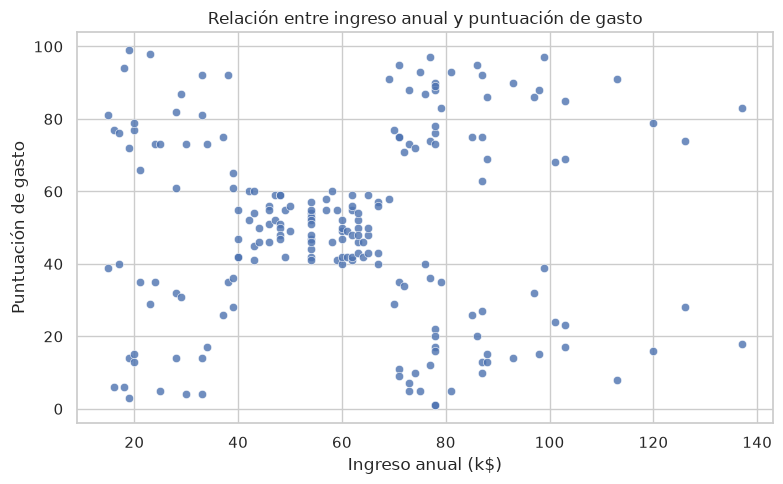

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    alpha=0.8
)

plt.title('Relación entre ingreso anual y puntuación de gasto', fontsize=12)
plt.xlabel('Ingreso anual (k$)')
plt.ylabel('Puntuación de gasto')
plt.tight_layout()
plt.show()

La correlación y el diagrama de dispersión sugieren que no existe una relación lineal clara entre el ingreso anual y la puntuación de gasto. La correlación es prácticamente cero (en el conjunto clásico de Mall Customers, ronda 0.01), y en la gráfica se ven puntuaciones de gasto altas y bajas para distintos niveles de ingreso.

Esto significa que ganar más no necesariamente implica gastar más, al menos según estas dos variables. La gráfica sí podría mostrar grupos de clientes, pero la correlación por sí sola no los identifica. Tampoco demuestra causalidad.

# 5. ¿Cómo varía la puntuación de gasto en diferentes grupos de ingresos anuales?

Objetivo: Examinar cómo los clientes en diferentes rangos de ingresos se comportan en términos de gasto.

Respuesta esperada: Una gráfica de cajas o de violín que muestre la Spending Score (1-100) para diferentes rangos de Annual Income (k$).

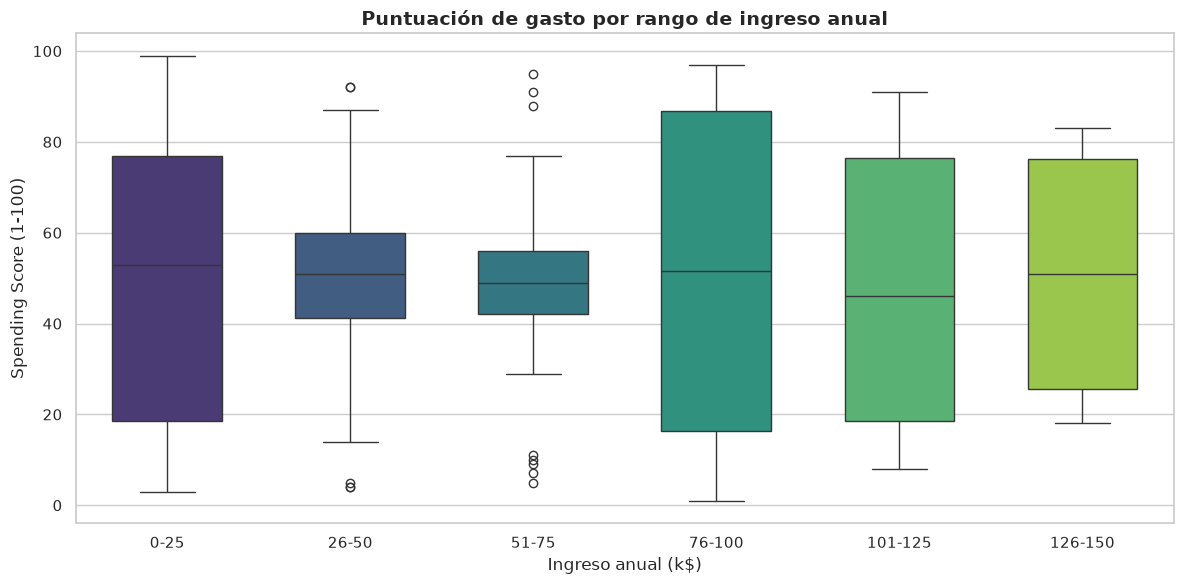

In [9]:
# Crear grupos de ingreso anual
df['Income Group'] = pd.cut(
    df['Annual Income (k$)'],
    bins=[0, 25, 50, 75, 100, 125, 150],
    labels=['0-25', '26-50', '51-75', '76-100', '101-125', '126-150'],
    right=False
)

# Visualización: distribución de la puntuación de gasto por rango de ingresos
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x='Income Group',
    y='Spending Score (1-100)',
    palette='viridis',
    width=0.6
)

plt.title('Puntuación de gasto por rango de ingreso anual', fontsize=14, fontweight='bold')
plt.xlabel('Ingreso anual (k$)')
plt.ylabel('Spending Score (1-100)')
plt.tight_layout()
plt.show()

In [ ]:
### Conclusión de la gráfica

La gráfica de puntuación de gasto por rango de ingreso anual muestra que el gasto no aumenta de manera uniforme a medida que crece el ingreso. Aunque algunos grupos con ingresos medios y altos presentan puntuaciones de gasto más altas, la variabilidad dentro de cada rango es considerable, lo que indica que el ingreso anual por sí solo no explica completamente el comportamiento de consumo.

En general, se observa una superposición entre los diferentes grupos, con clientes de ingresos bajos, medios y altos distribuidos en distintos niveles de gasto. Esto sugiere que factores adicionales —como el perfil del cliente, sus hábitos de compra y sus preferencias— también influyen de manera importante en la puntuación de gasto.

En conclusión, el ingreso anual es un indicador útil, pero no determinante: hay clientes con ingresos modestos que gastan mucho y clientes con ingresos altos que gastan menos, lo que refleja una relación compleja y no lineal entre ambos aspectos.

# 6. ¿Cuál es la proporción de clientes por género?

Objetivo: Determinar el balance de género en el conjunto de datos.

Respuesta esperada: Una gráfica de barras o un gráfico de pastel que muestre la proporción de hombres y mujeres.

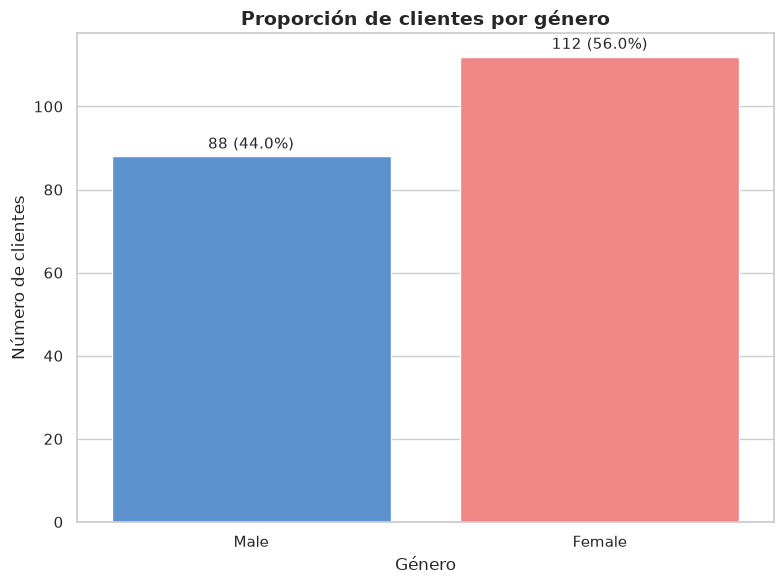

In [10]:
# Proporción de clientes por género
gender_counts = df['Gender'].value_counts().reindex(['Male', 'Female'], fill_value=0)
percentages = gender_counts / gender_counts.sum() * 100

plt.figure(figsize=(8, 6))
ax = sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values,
    palette=['#4a90e2', '#ff7675']
)

plt.title('Proporción de clientes por género', fontsize=14, fontweight='bold')
plt.xlabel('Género')
plt.ylabel('Número de clientes')

for i, (count, pct) in enumerate(zip(gender_counts.values, percentages.values)):
    ax.text(i, count + 1, f'{count} ({pct:.1f}%)', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

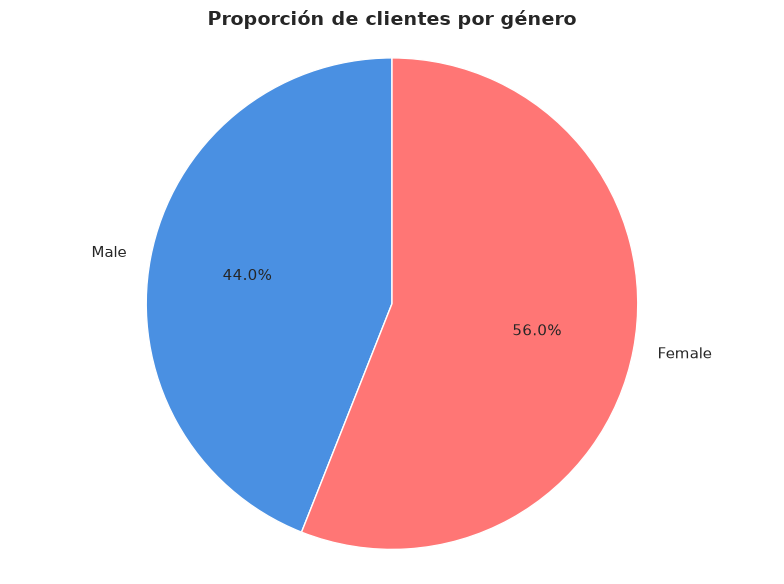

In [11]:
plt.figure(figsize=(8, 6))

colors = ['#4a90e2', '#ff7675']
wedges, texts, autotexts = plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    textprops={'fontsize': 11}
)

plt.title('Proporción de clientes por género', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.tight_layout()
plt.show()

# 7. Qué grupos de edad gastan más en promedio?

Objetivo: Identificar los grupos de edad que tienen una mayor puntuación de gasto en promedio. 

Gasto promedio por grupo de edad:
Age Group
26-35    64.450000
18-25    54.947368
66-75    47.250000
36-45    44.833333
46-55    36.702703
56-65    32.117647
Name: Spending Score (1-100), dtype: float64


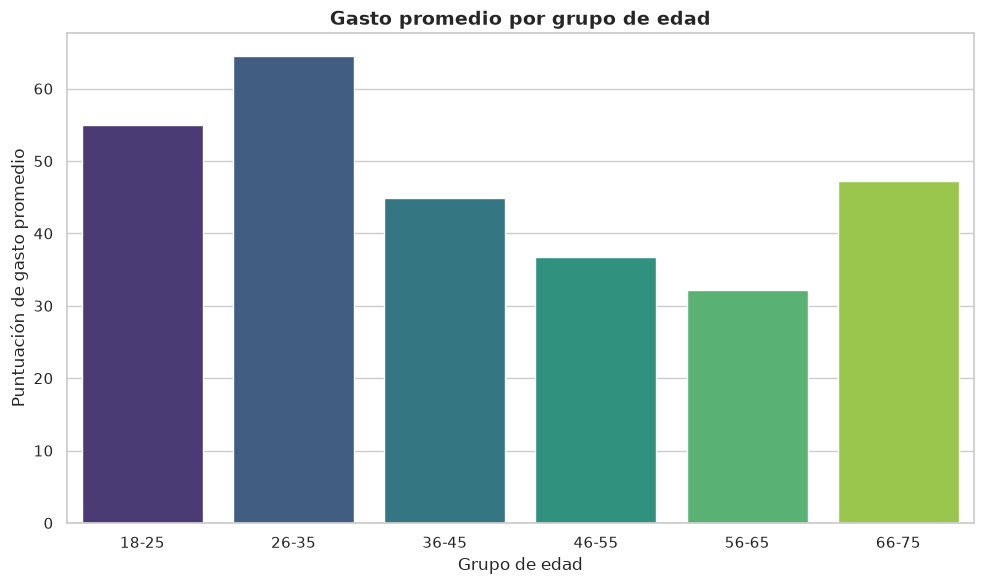

In [12]:
# Agrupar edades para analizar el gasto promedio por rango
age_bins = [18, 25, 35, 45, 55, 65, 75]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '66-75']
df['Age Group'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels, include_lowest=True)

# Calcular el gasto promedio por grupo de edad
spending_by_age_group = (
    df.groupby('Age Group', observed=True)['Spending Score (1-100)']
      .mean()
      .sort_values(ascending=False)
)

print("Gasto promedio por grupo de edad:")
print(spending_by_age_group)

# Visualización
plt.figure(figsize=(10, 6))
sns.barplot(
    x=spending_by_age_group.index,
    y=spending_by_age_group.values,
    palette='viridis'
)

plt.title('Gasto promedio por grupo de edad', fontsize=14, fontweight='bold')
plt.xlabel('Grupo de edad')
plt.ylabel('Puntuación de gasto promedio')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
### Conclusión de la gráfica

La gráfica de gasto promedio por grupo de edad muestra que los clientes del rango de 26 a 35 años son los que más gastan en promedio, con una puntuación de aproximadamente 64.45 puntos. Le sigue el grupo de 18 a 25 años, con alrededor de 54.95, lo que indica que los consumidores más jóvenes y adultos jóvenes tienen un comportamiento de gasto más activo.

A medida que aumenta la edad, la puntuación de gasto tiende a disminuir: los grupos de 36 a 45, 46 a 55 y 56 a 65 años muestran valores progresivamente menores, llegando a 32.12 puntos en el rango de 56 a 65 años. Esto sugiere que el interés por gastar más fuerte se concentra principalmente en los adultos jóvenes, mientras que en edades mayores el comportamiento de compra es más moderado.

En conclusión, la edad es un factor relevante para segmentar el gasto: los clientes más jóvenes y de mediana edad presentan mayor potencial de consumo, mientras que los grupos de mayor edad muestran puntuaciones de gasto más bajas en promedio.

# 8. ¿Hay alguna relación entre la edad y el ingreso anual de los clientes?

Objetivo: Explorar si hay una tendencia entre la edad de los clientes y sus ingresos.

Respuesta esperada: Una gráfica de dispersión que muestre la relación entre Age y Annual Income (k$).

La correlación entre edad e ingreso anual es: -0.012


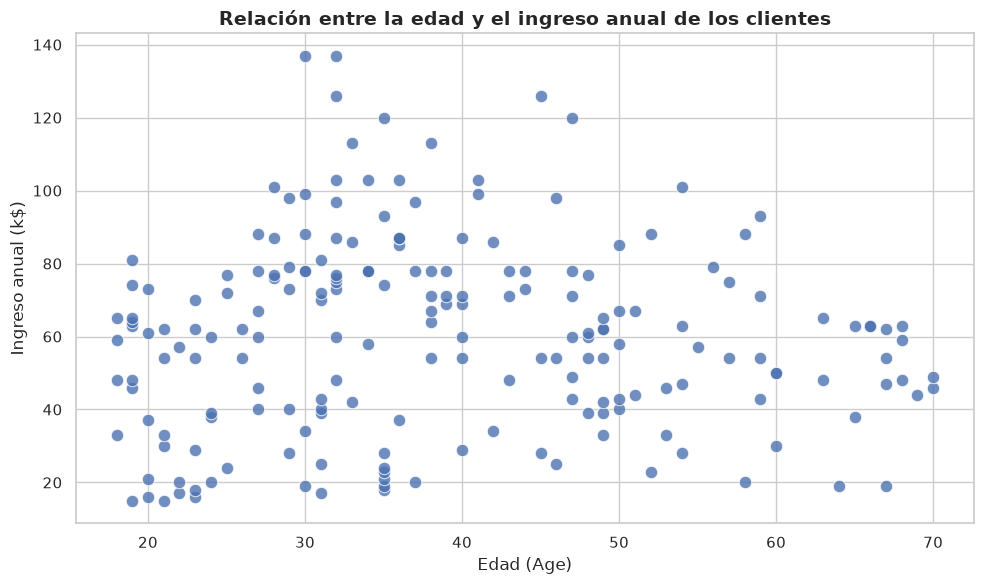

In [13]:
# Relación entre edad e ingreso anual
age_income_corr = df['Age'].corr(df['Annual Income (k$)'])
print(f'La correlación entre edad e ingreso anual es: {age_income_corr:.3f}')

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Age',
    y='Annual Income (k$)',
    alpha=0.8,
    s=80
)

plt.title('Relación entre la edad y el ingreso anual de los clientes', fontsize=14, fontweight='bold')
plt.xlabel('Edad (Age)', fontsize=12)
plt.ylabel('Ingreso anual (k$)', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
### Conclusión de la gráfica

La gráfica de dispersión entre edad e ingreso anual muestra que no existe una relación lineal clara entre ambas variables. El coeficiente de correlación es prácticamente cero (`-0.012`), lo que indica que la edad por sí sola no explica el nivel de ingresos de los clientes.

Además, los puntos se distribuyen de forma muy dispersa en todo el rango de edades, con clientes jóvenes y mayores apareciendo tanto en niveles de ingreso bajos como altos. Esto sugiere que factores como la profesión, la experiencia laboral, la educación o el tipo de cliente tienen un impacto más importante que la edad.

En resumen, la edad no es un predictor fuerte del ingreso anual en este conjunto de datos y la relación entre ambas variables es débil y poco estructurada.

# 9. ¿Cuál es la distribución conjunta de la edad y el ingreso anual?

Objetivo: Entender cómo se distribuyen estas dos variables en conjunto.

Respuesta esperada: Una gráfica de dispersión con una densidad de puntos o un gráfico de hexágonos que muestre la distribución conjunta de Age y Annual Income (k$).

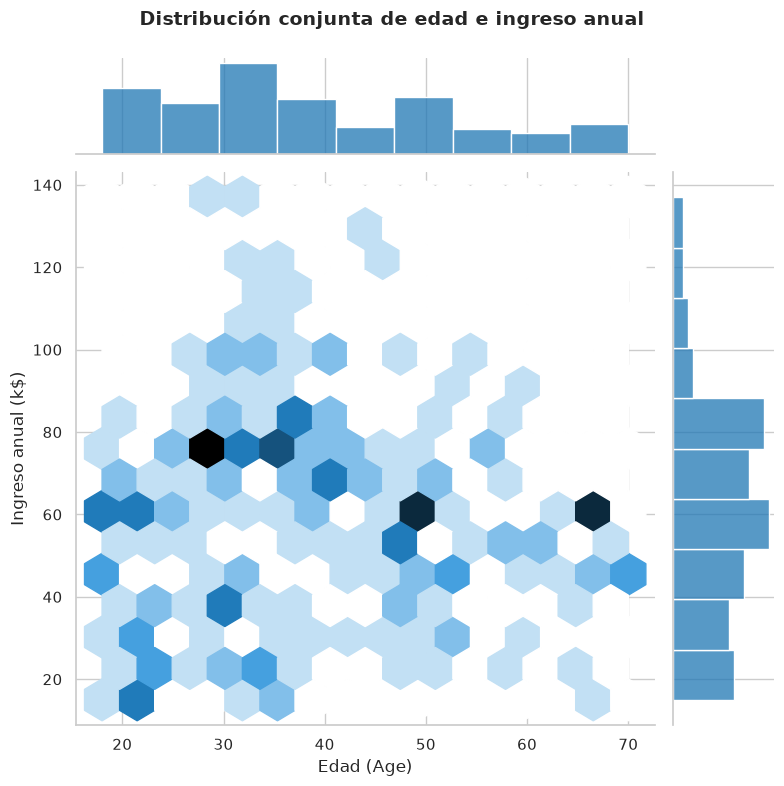

In [14]:
# Distribución conjunta de edad e ingreso anual
g = sns.jointplot(
    data=df,
    x='Age',
    y='Annual Income (k$)',
    kind='hex',
    height=8,
    gridsize=15,
    color='#1f77b4'
)

g.fig.suptitle('Distribución conjunta de edad e ingreso anual', fontsize=14, fontweight='bold')
g.set_axis_labels('Edad (Age)', 'Ingreso anual (k$)')
g.fig.tight_layout()
g.fig.subplots_adjust(top=0.92)
plt.show()

In [ ]:
### Conclusión de la gráfica de hexágonos

La gráfica de hexágonos de `Age` vs `Annual Income (k$)` muestra que la relación entre ambas variables es débil y poco estructurada. No se observa una tendencia clara de que la edad determine directamente el ingreso anual, ya que los puntos se distribuyen de forma bastante dispersa en todo el rango de edades.

La mayor concentración de clientes aparece en edades jóvenes y adultas tempranas, con ingresos que van desde valores bajos hasta moderadamente altos, mientras que en edades mayores la dispersión sigue siendo amplia. Esto sugiere que el ingreso anual no depende únicamente de la edad, sino que también hay otros factores (como la profesión, el nivel educativo, la experiencia laboral o el tipo de cliente) que influyen en el comportamiento observado.

En resumen, la gráfica refleja una distribución heterogénea y la ausencia de un patrón lineal claro entre edad e ingresos. Por lo tanto, la edad por sí sola no es un predictor fuerte del ingreso anual en este conjunto de datos.

# 10. ¿Cómo se distribuyen los clientes en función de la puntuación de gasto y el género?

Objetivo: Analizar la relación entre la puntuación de gasto y el género.

Respuesta esperada: Una gráfica de dispersión o un gráfico de violín que muestre la Spending Score (1-100) separada por género.

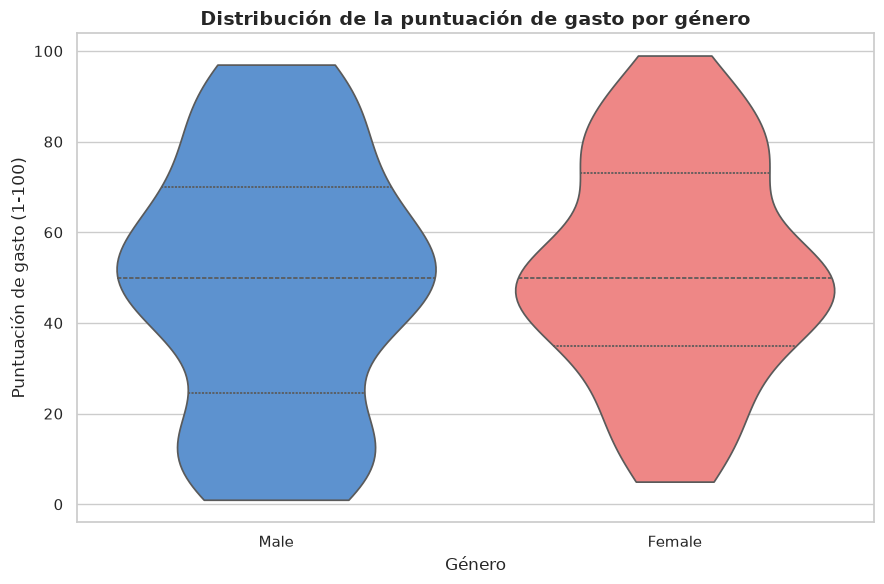

In [15]:
plt.figure(figsize=(9, 6))

sns.violinplot(
    data=df,
    x='Gender',
    y='Spending Score (1-100)',
    order=['Male', 'Female'],
    palette={'Male': '#4a90e2', 'Female': '#ff7675'},
    inner='quartile',
    cut=0
)

plt.title('Distribución de la puntuación de gasto por género', fontsize=14, fontweight='bold')
plt.xlabel('Género')
plt.ylabel('Puntuación de gasto (1-100)')
plt.tight_layout()
plt.show()

In [ ]:
### Conclusión de la gráfica

La distribución por género muestra que el conjunto de datos está relativamente equilibrado, pero con una ligera mayoría de mujeres: 112 mujeres (56.0%) frente a 88 hombres (44.0%).

Esto indica que, aunque no hay una diferencia extrema, la muestra está levemente sesgada hacia el segmento femenino. Dado que la proporción es bastante cercana a la igualdad, se puede concluir que el género no presenta un desbalance fuerte en la base de datos y que las comparaciones entre grupos pueden hacerse de forma razonablemente representativa.